# LIBRARIES

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

# DATA PREPROCESSING

In [4]:
filepath = "Student_Depression_Dataset.csv"

* Split df into num_df and cat_df
* On num_df >> Missing Value > Duplicates > Scaling
* On cat_df >> Missing Value > Duplicates > Encoding

In [5]:
df = pd.read_csv(filepath)

df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [6]:
df.shape

(4464, 13)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB


In [8]:
df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [10]:
df.describe(include="object")

C:\Users\hp\AppData\Local\Temp\ipykernel_988\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Gender,Family_background,Relationship_status,Marital_status,Living_style,friend_circle,Health_condition,Home_division,Depression
count,4464,4464,4464,4464,4464,4464,4464,4464,4464
unique,2,3,3,3,2,2,4,8,2
top,Female,Middle class,Single,Unmarried,Bachelor,Yes,Normal,Dhaka,No
freq,2462,2642,2803,3619,2449,3215,1787,1527,3263


In [11]:
num_df = df.select_dtypes(include="number")
cat_df = df.select_dtypes(include="object")

C:\Users\hp\AppData\Local\Temp\ipykernel_988\192251176.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_df = df.select_dtypes(include="object")


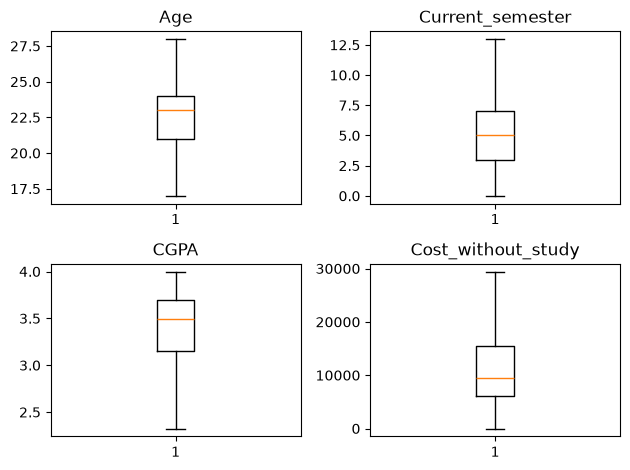

In [18]:
for i, col in enumerate(num_df.columns, 1):
  plt.subplot(2, 2, i)
  plt.boxplot(df[col])
  plt.title(col)
plt.tight_layout()
plt.show()


# DATA CLEANING

In [13]:
num_df.isnull().sum()

Age                   0
Current_semester      0
CGPA                  0
Cost_without_study    0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
cat_df.isnull().sum()

Gender                 0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
friend_circle          0
Health_condition       0
Home_division          0
Depression             0
dtype: int64

## OUTLIER HANDLING

In [16]:
cols = ["CGPA", "Cost_without_study"]

for col in cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)

  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  df[col] = df[col].clip(lower, upper)

# ENCODING

## 1. LABEL ENCODING

In [19]:
# Depression is our target here

le = LabelEncoder()

df["Depression"] = le.fit_transform(df["Depression"])

df["Depression"].unique()

array([1, 0])

## 2. ORDINAL ENCODING

In [20]:
df["Health_condition"].unique()  # order is normal > good > abnormal > critical (Ordinal Encoding)

<StringArray>
['Critical', 'Abnormal', 'Good', 'Normal']
Length: 4, dtype: str

In [21]:
enc_health = OrdinalEncoder(
    categories = [["Normal", "Good", "Abnormal", "Critical"]]
)

df["Health_condition"] = enc_health.fit_transform(df[["Health_condition"]])

In [22]:
df["Family_background"].unique() # order is lower middle class > middle class > rich class

<StringArray>
['Middle class', 'Lower Middle class', 'Rich class']
Length: 3, dtype: str

In [23]:
enc_fam = OrdinalEncoder(
    categories = [["Lower Middle class", "Middle class", "Rich class"]]
)

df["Family_background"] = enc_fam.fit_transform(df[["Family_background"]])

## 3. ONE HOT ENCODING

In [24]:
# one hot encoding for all othet categorical columns
enc_gender = OneHotEncoder()

enc_gender_data = enc_gender.fit_transform(df[["Gender"]])

enc_gender_df = pd.DataFrame(
    enc_gender_data.toarray(),
    columns = enc_gender.get_feature_names_out(["Gender"]),
    index = df.index
)

df = pd.concat([df.drop('Gender', axis=1), enc_gender_df], axis=1)

In [25]:
enc_relstatus = OneHotEncoder()

enc_relstatus_data = enc_relstatus.fit_transform(df[["Relationship_status"]])

enc_relstatus_df = pd.DataFrame(
    enc_relstatus_data.toarray(),
    columns = enc_relstatus.get_feature_names_out(["Relationship_status"]),
    index = df.index
)

df = pd.concat([df.drop("Relationship_status", axis=1), enc_relstatus_df], axis=1)

In [26]:
enc_marstatus = OneHotEncoder()

enc_marstatus_data = enc_marstatus.fit_transform(df[["Marital_status"]])

enc_marstatus_df = pd.DataFrame(
    enc_marstatus_data.toarray(),
    columns = enc_marstatus.get_feature_names_out(["Marital_status"]),
    index = df.index
)

df = pd.concat([df.drop("Marital_status", axis=1), enc_marstatus_df], axis=1)

In [27]:
enc_living = OneHotEncoder()

enc_living_data = enc_living.fit_transform(df[["Living_style"]])

enc_living_df = pd.DataFrame(
    enc_living_data.toarray(),
    columns = enc_living.get_feature_names_out(["Living_style"]),
    index = df.index
)

df = pd.concat([df.drop("Living_style", axis=1), enc_living_df], axis=1)

In [28]:
enc_friend = OneHotEncoder()

enc_friend_data = enc_friend.fit_transform(df[["friend_circle"]])

enc_friend_df = pd.DataFrame(
    enc_friend_data.toarray(),
    columns = enc_friend.get_feature_names_out(["friend_circle"]),
    index = df.index
)

df = pd.concat([df.drop("friend_circle", axis=1), enc_friend_df], axis=1)

In [29]:
enc_home = OneHotEncoder()

enc_home_data = enc_home.fit_transform(df[["Home_division"]])

enc_home_df = pd.DataFrame(
    enc_home_data.toarray(),
    columns = enc_home.get_feature_names_out(["Home_division"]),
    index = df.index
)

df = pd.concat([df.drop("Home_division", axis=1), enc_home_df], axis=1)

## STANDARDISATION

In [30]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(num_df)

df[num_df.columns] = scaled_data

In [31]:
df.head()

,Age,Family_background,Current_semester,CGPA,Health_condition,Cost_without_study,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,...,friend_circle_No,friend_circle_Yes,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
0,-0.306105,1.0,1.007991,0.044732,3.0,-0.170193,1,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-1.789232,1.0,-1.319225,0.745009,2.0,0.387388,1,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.188270,1.0,1.007991,-0.344311,2.0,0.633645,1,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,-1.294857,1.0,-1.319225,0.926563,1.0,0.929304,0,0.0,1.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,-0.800481,1.0,-1.707095,1.523095,2.0,0.820861,1,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
